In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pandas import read_csv
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error


tf.keras.utils.set_random_seed(42)  # sets seeds for base-python, numpy and tf
tf.config.experimental.enable_op_determinism()


# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-look_back-1):
		a = dataset[i:(i+look_back), 0]
		dataX.append(a)
		dataY.append(dataset[i + look_back, 0])
	return np.array(dataX), np.array(dataY)


def inverse_transform(scaler, data, dataset_shape):
    zeros = np.zeros((data.shape[0], dataset_shape[1] - 1))
    concatenated = np.concatenate((data, zeros), axis=1)
    return scaler.inverse_transform(concatenated)[:, 0]


def calculate_metrics(actual, predicted, dataset_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(f'{dataset_name} MAE: {mae}, {dataset_name} RMSE: {rmse}')
    return mae, rmse

# load the dataset
dataframe = read_csv('../preprocess/parking_time_series_with_features_15min.csv', usecols=[1], engine='python')
dataset = dataframe.values
dataset = dataset.astype('float32')

      Parkings
0            1
1            1
2            1
3            1
4            1
...        ...
9212         4
9213         3
9214         1
9215         1
9216         1

[9217 rows x 1 columns]


In [97]:
# Normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# Split into train and test sets
train_size = int(len(dataset) * 0.70)
validation_size = int(len(dataset) * 0.15)
test_size = int(len(dataset) * 0.15)

train_df = dataset[0:train_size]
validation_df = dataset[train_size:train_size+validation_size]
test_df = dataset[train_size+validation_size:]

look_back = 96
trainX, trainY = create_dataset(train_df, look_back)
validationX, validationY = create_dataset(validation_df, look_back)
testX, testY = create_dataset(test_df, look_back)


# Reshape input to be [samples, time steps, features]
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
validationX = np.reshape(validationX, (validationX.shape[0], 1, validationX.shape[1]))
testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))

# create and fit the LSTM network
model = Sequential()
model.add(LSTM(4, input_shape=(1, look_back), dropout=0.2, recurrent_dropout=0.1))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam')

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = model.fit(trainX, trainY, validation_data=(validationX, validationY), epochs=100, batch_size=1, verbose=2, callbacks=[early_stopping])

Epoch 1/100


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


6354/6354 - 3s - 485us/step - loss: 0.0084 - val_loss: 0.0038
Epoch 2/100
6354/6354 - 2s - 366us/step - loss: 0.0042 - val_loss: 0.0066
Epoch 3/100
6354/6354 - 2s - 362us/step - loss: 0.0041 - val_loss: 0.0059
Epoch 4/100
6354/6354 - 2s - 371us/step - loss: 0.0037 - val_loss: 0.0046
Epoch 5/100
6354/6354 - 2s - 387us/step - loss: 0.0036 - val_loss: 0.0078
Epoch 6/100
6354/6354 - 3s - 428us/step - loss: 0.0034 - val_loss: 0.0071
Epoch 7/100
6354/6354 - 3s - 430us/step - loss: 0.0033 - val_loss: 0.0087
Epoch 8/100
6354/6354 - 2s - 372us/step - loss: 0.0032 - val_loss: 0.0052
Epoch 9/100
6354/6354 - 2s - 379us/step - loss: 0.0032 - val_loss: 0.0065
Epoch 10/100
6354/6354 - 2s - 383us/step - loss: 0.0030 - val_loss: 0.0071
Epoch 11/100
6354/6354 - 2s - 377us/step - loss: 0.0030 - val_loss: 0.0069


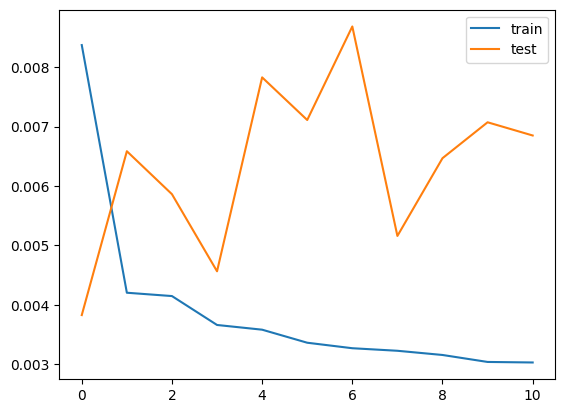

In [98]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 748us/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 428us/step
Train MAE: 47.19571520781258, Train RMSE: 74.1628701623744
Validation MAE: 63.65910555817325, Validation RMSE: 86.93760370249711
Test MAE: 61.642626370276986, Test RMSE: 82.51302004461165


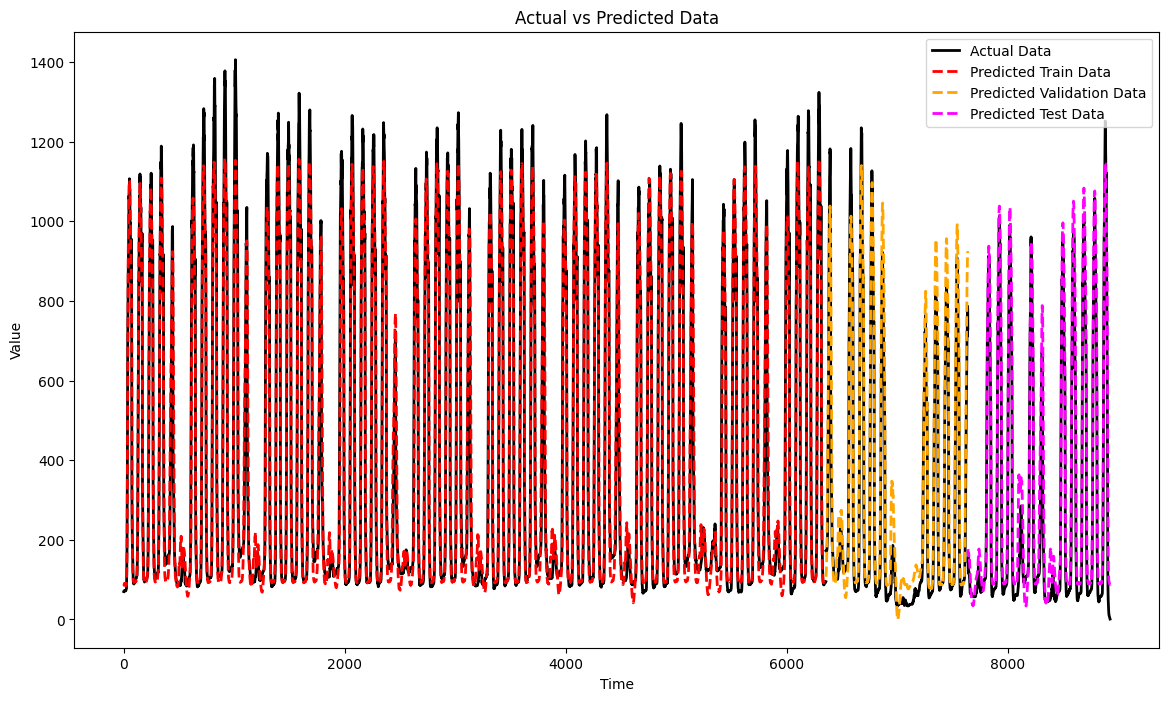

In [99]:

# Predictions
trainPredict = model.predict(trainX)
validationPredict = model.predict(validationX)
testPredict = model.predict(testX)


# Inverse transform predictions and actual values to original scale
train_predict = inverse_transform(scaler, trainPredict, dataset.shape)
validation_predict = inverse_transform(scaler, validationPredict, dataset.shape)
test_predict = inverse_transform(scaler, testPredict, dataset.shape)
trainY_actual = inverse_transform(scaler, trainY.reshape(-1, 1), dataset.shape)
validationY_actual = inverse_transform(scaler, validationY.reshape(-1, 1), dataset.shape)
testY_actual = inverse_transform(scaler, testY.reshape(-1, 1), dataset.shape)

# Calculate and print MAE and RMSE
train_mae, train_rmse = calculate_metrics(trainY_actual, train_predict, 'Train')
validation_mae, validation_rmse = calculate_metrics(validationY_actual, validation_predict, 'Validation')
test_mae, test_rmse = calculate_metrics(testY_actual, test_predict, 'Test')


# Plot the results
plt.figure(figsize=(14, 8))

# Actual Data
plt.plot(trainY_actual, label='Actual Data', color='black', linestyle='-', linewidth=2)
plt.plot(range(len(trainY_actual), len(trainY_actual) + len(validationY_actual)), validationY_actual, color='black', linestyle='-', linewidth=2)
plt.plot(range(len(trainY_actual) + len(validationY_actual), len(trainY_actual) + len(validationY_actual) + len(testY_actual)), testY_actual, color='black', linestyle='-', linewidth=2)

# Predicted Data
plt.plot(train_predict, label='Predicted Train Data', color='red', linestyle='--', linewidth=2)
plt.plot(range(len(trainY_actual), len(trainY_actual) + len(validationY_actual)), validation_predict, label='Predicted Validation Data', color='orange', linestyle='--', linewidth=2)
plt.plot(range(len(trainY_actual) + len(validationY_actual), len(trainY_actual) + len(validationY_actual) + len(test_predict)), test_predict, label='Predicted Test Data', color='magenta', linestyle='--', linewidth=2)

plt.xlabel('Time')
plt.ylabel('Value')
plt.title('Actual vs Predicted Data')
plt.legend()
plt.show()